# End-to-end pipeline: batch correction, biomarker inference and classifier training

This notebook combines the original `biomarkers_inference.ipynb` (V gene usage correction, resampling, biomarker detection and clustering) and `grid_search_clf.ipynb` (classifier training and evaluation) into a single workflow.

The first part reproduces the biomarker inference logic; the second part performs grid-search-based training and assessment of COVID-19 status classifiers using the inferred biomarkers.

In [1]:
from mir.common.parser import *
from mir.common.repertoire import Repertoire
from mir.common.repertoire_dataset import RepertoireDataset
from mir.common.clonotype_dataset import ClonotypeDataset
from mir.basic.segment_usage import *
from mir.basic.sampling import RepertoireSampling
from pympler.asizeof import asizeof
from mir.biomarkers.fisher_biomarkers_detector import FisherBiomarkersDetector
import time

/home/evlasova/.conda/envs/bio2025/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/evlasova/.conda/envs/bio2025/lib/python3.12/site-packages/numpy/core/getlimits.py:549: UserWarning: The value of the smallest subnormal for <class 'numpy.float64'> type is zero.
  setattr(self, word, getattr(machar, word).flat[0])
/home/evlasova/.conda/envs/bio2025/lib/python3.12/site-packages/numpy/core/getlimits.py:89: UserWarning: The value of the smallest subnormal for <class 'numpy.float64'> type is zero.
  return self._float_to_str(self.smallest_subnormal)
/home/evlasova/.conda/envs/bio2025/lib/python3.12/site-packages/numpy/core/getlimits.py:549: UserWarning: The value of the smallest subnormal for <class 'numpy.float32'> type is zero.
  setattr(self, word, getattr(machar, word).flat[0])
/home/evlasova/.conda

In [2]:
metadata = pd.read_csv('../data/desc_fmba_not_nan_hla.csv').drop(columns=['Unnamed: 0'])
metadata

,run,reads,clonotypes,singletons,doubletons,file.id,sequencingDate,folder,R1,R2,...,HLA-DQB1.2,HLA-DRB1.1,HLA-DRB1.2,id,subsequent_sequencing,HLA-DRB4.1,HLA-DRB3.1,HLA-DRB5.1,gene,is.bad.reseq
0,020000010808_S3_L001.clonotypes.TRB.txt,623811,4324,491,263,020000010808_S3_L001,2020 10 19,2020/10_FMBA_NovaSeq5,020000010808_S3_L001_R1_001.fastq.gz,020000010808_S3_L001_R2_001.fastq.gz,...,DQB1*05:02,DRB1*11:04,DRB1*16:01,20000010,NaN,NaN,NaN,NaN,TRB,NaN
1,020000110808_S14_L001.clonotypes.TRB.txt,13119545,13264,573,219,020000110808_S14_L001,2020 09 05,2020/09_FMBA_NovaSeq_DNA,020000110808_S14_L001_R1_001.fastq.gz,020000110808_S14_L001_R2_001.fastq.gz,...,DQB1*06:02,DRB1*01:01,DRB1*15:01,20000110,NaN,NaN,NaN,NaN,TRB,NaN
2,020000190808_S27_L001.clonotypes.TRB.txt,6942203,16977,1198,550,020000190808_S27_L001,2020 10 19,2020/10_FMBA_NovaSeq5,020000190808_S27_L001_R1_001.fastq.gz,020000190808_S27_L001_R2_001.fastq.gz,...,DQB1*06:01,DRB1*07:01,DRB1*15:02,20000190,NaN,NaN,NaN,NaN,TRB,NaN
3,020000200808_S181_L002.clonotypes.TRB.txt,6583555,14220,916,420,020000200808_S181_L002,2020 10 19,2020/10_FMBA_NovaSeq5,020000200808_S181_L002_R1_001.fastq.gz,020000200808_S181_L002_R2_001.fastq.gz,...,DQB1*05:01,DRB1*01:01,DRB1*04:04,20000200,NaN,NaN,NaN,NaN,TRB,NaN
4,020000280808_S59_L001.clonotypes.TRB.txt,2005779,6144,477,260,020000280808_S59_L001,2020 10 19,2020/10_FMBA_NovaSeq5,020000280808_S59_L001_R1_001.fastq.gz,020000280808_S59_L001_R2_001.fastq.gz,...,DQB1*05:01,DRB1*01:03,DRB1*13:03,20000280,NaN,NaN,NaN,NaN,TRB,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
951,780008510808_S152_L002.clonotypes.TRB.txt,125864,7215,1173,793,780008510808_S152_L002,2020 09 27,2020/09_FMBA_NovaSeq3_DNA,780008510808_S152_L002_R1_001.fastq.gz,780008510808_S152_L002_R2_001.fastq.gz,...,DQB1*06:02,DRB1*07:01,DRB1*15:01,780008510,NaN,NaN,NaN,NaN,TRB,NaN
952,780008550808_S150_L002.clonotypes.TRB.txt,3070841,8864,398,150,780008550808_S150_L002,2020 09 27,2020/09_FMBA_NovaSeq3_DNA,780008550808_S150_L002_R1_001.fastq.gz,780008550808_S150_L002_R2_001.fastq.gz,...,DQB1*06:02,DRB1*04:01,DRB1*15:01,780008550,NaN,NaN,NaN,NaN,TRB,NaN
953,910000140808_S123_L002.clonotypes.TRB.txt,3095012,27443,1318,643,910000140808_S123_L002,2020 09 28,2020/09_FMBA_NovaSeq2_DNA,910000140808_S123_L002_R1_001.fastq.gz,910000140808_S123_L002_R2_001.fastq.gz,...,DQB1*02:02,DRB1*03:01,DRB1*07:01,910000140,NaN,NaN,NaN,NaN,TRB,NaN
954,910000320808_S121_L002.clonotypes.TRB.txt,203560,11451,2013,1299,910000320808_S121_L002,2020 09 28,2020/09_FMBA_NovaSeq2_DNA,910000320808_S121_L002_R1_001.fastq.gz,910000320808_S121_L002_R2_001.fastq.gz,...,DQB1*05:01,DRB1*01:02,DRB1*07:01,910000320,NaN,NaN,NaN,NaN,TRB,NaN


In [3]:
metadata.folder.value_counts()

folder
2020/12_FMBA_Novaseq8_DNA    157
2020/10_FMBA_NovaSeq5        145
2020/12_FMBA_Novaseq7_DNA    124
2020/09_FMBA_NovaSeq_DNA     118
2020/10_FMBA_NovaSeq6        116
2020/10_FMBA_NovaSeq4        106
2020/09_FMBA_NovaSeq2_DNA     96
2020/09_FMBA_NovaSeq3_DNA     94
Name: count, dtype: int64

In [4]:
metadata = metadata[metadata.folder.isin(
    ['2020/10_FMBA_NovaSeq5', '2020/10_FMBA_NovaSeq6', '2020/12_FMBA_Novaseq7_DNA', '2020/12_FMBA_Novaseq8_DNA'])].reset_index(drop=True)

In [5]:
dataset = RepertoireDataset.load(parser=VDJtoolsParser(sep=','), 
                                 metadata=metadata,
                                 threads=32,
                                 gene='TRB',
                                 paths=[f'/projects/fmba_covid/publication/fmba/{r["run"]}' for _, r in metadata.iterrows()])

loading Repertoire objects: 100%|██████████| 542/542 [00:50<00:00, 10.76it/s]


In [6]:
folder_to_run_mapping = {}
for folder in dataset.metadata[['run', 'folder']].folder.unique():
    folder_to_run_mapping[folder] = set(dataset.metadata[dataset.metadata.folder == folder].run)

In [7]:
z_score_usage_table_v = StandardizedSegmentUsageTable.load_from_repertoire_dataset(
    repertoire_dataset=dataset, 
    gene='TRB', 
    segment_type='V', 
    group_mapping=folder_to_run_mapping, 
    metadata_column_for_group_mapping_name='run',
    standardization_method='log_exp')
z_score_usage_table_j = StandardizedSegmentUsageTable.load_from_repertoire_dataset(
    repertoire_dataset=dataset, 
    gene='TRB', 
    segment_type='J', 
    group_mapping=folder_to_run_mapping, 
    metadata_column_for_group_mapping_name='run',
    standardization_method='log_exp')

In [8]:
t0 = time.time()
dataset = dataset.resample(updated_segment_usage_tables=[z_score_usage_table_v, z_score_usage_table_j], 
                                    threads=32)
print(time.time() - t0)

repertoire resampling in progress: 100%|██████████| 542/542 [02:16<00:00,  3.98it/s]


138.94704675674438


In [9]:
dataset

There are 542 repertoires in the dataset
                                         run    reads  clonotypes  singletons  \
0    020000010808_S3_L001.clonotypes.TRB.txt   623811        4324         491   
1   020000190808_S27_L001.clonotypes.TRB.txt  6942203       16977        1198   
2  020000200808_S181_L002.clonotypes.TRB.txt  6583555       14220         916   
3   020000280808_S59_L001.clonotypes.TRB.txt  2005779        6144         477   
4  020000330101_S185_L002.clonotypes.TRB.txt  4558846       10762        1218   

   doubletons                 file.id sequencingDate  \
0         263    020000010808_S3_L001     2020 10 19   
1         550   020000190808_S27_L001     2020 10 19   
2         420  020000200808_S181_L002     2020 10 19   
3         260   020000280808_S59_L001     2020 10 19   
4         336  020000330101_S185_L002     2020 12 18   

                      folder                                      R1  \
0      2020/10_FMBA_NovaSeq5    020000010808_S3_L001_R1_001.fas

In [10]:
dataset.clonotype_usage_matrix.clonotype_database_usage

clonotype usage matrix should be calculated. it would take a while
started public clonotypes extraction at 2025-11-17 23:14:33.569617
there are 658523 public clonotypes
finished public clonotypes extraction at 2025-11-17 23:16:37.156588
there are 658523 public clonotypes
created MultipleRepertoireDenseMatcher
started with 32 threads


repertoire dataset serialization: 542it [00:45, 11.79it/s]

all in all 542 reps, chunk size is 17, number of batches 32



clonotype usage matrix preparation: 100%|██████████| 32/32 [03:16<00:00,  6.14s/it]


<Compressed Sparse Column sparse array of dtype 'float64'
	with 43762232 stored elements and shape (542, 658523)>

In [11]:
dataset.metadata.COVID_status

0        COVID
1        COVID
2      healthy
3        COVID
4      healthy
        ...   
537      COVID
538      COVID
539      COVID
540      COVID
541      COVID
Name: COVID_status, Length: 542, dtype: object

In [13]:
for i in range(542):
    dataset.deserialize_repertoire(i)

In [14]:
covid_pos_rd, covid_neg_rd = dataset.split_by_metadata_function(
        splitting_method=lambda x: x.COVID_status == 'COVID'
    )

In [15]:
covid_pos_rd

There are 352 repertoires in the dataset
                                        run    reads  clonotypes  singletons  \
0   020000010808_S3_L001.clonotypes.TRB.txt   623811        4324         491   
1  020000190808_S27_L001.clonotypes.TRB.txt  6942203       16977        1198   
2  020000280808_S59_L001.clonotypes.TRB.txt  2005779        6144         477   
3  020000340808_S82_L001.clonotypes.TRB.txt  6526027        7386         433   
4  020000420808_S51_L001.clonotypes.TRB.txt  5624600       16116        1007   

   doubletons                file.id sequencingDate                 folder  \
0         263   020000010808_S3_L001     2020 10 19  2020/10_FMBA_NovaSeq5   
1         550  020000190808_S27_L001     2020 10 19  2020/10_FMBA_NovaSeq5   
2         260  020000280808_S59_L001     2020 10 19  2020/10_FMBA_NovaSeq5   
3         218  020000340808_S82_L001     2020 10 19  2020/10_FMBA_NovaSeq5   
4         482  020000420808_S51_L001     2020 10 19  2020/10_FMBA_NovaSeq5   

         

In [16]:
covid_neg_rd

There are 190 repertoires in the dataset
                                         run    reads  clonotypes  singletons  \
0  020000200808_S181_L002.clonotypes.TRB.txt  6583555       14220         916   
1  020000330101_S185_L002.clonotypes.TRB.txt  4558846       10762        1218   
2  020000350808_S126_L002.clonotypes.TRB.txt  4539391       13345        1062   
3  020000360808_S102_L002.clonotypes.TRB.txt  3935818       18453        1393   
4  020000390808_S189_L002.clonotypes.TRB.txt  4116820       12138         630   

   doubletons                 file.id sequencingDate  \
0         420  020000200808_S181_L002     2020 10 19   
1         336  020000330101_S185_L002     2020 12 18   
2         445  020000350808_S126_L002     2020 10 19   
3         731  020000360808_S102_L002     2020 10 19   
4         318  020000390808_S189_L002     2020 10 19   

                      folder                                      R1  \
0      2020/10_FMBA_NovaSeq5  020000200808_S181_L002_R1_001.fas

In [17]:
fbd = FisherBiomarkersDetector(control_repertoire_dataset=covid_neg_rd,
                               ill_repertoire_dataset=covid_pos_rd, 
                               adjusted_p_value=0.05, 
                               threads=28)

created a fisher biomarker detector with 28 threads


In [18]:
t0 = time.time()
biomarkers = fbd.detect_biomarkers(adjusted_p_value=0.05)
print(time.time() - t0)

clonotype usage matrix should be calculated. it would take a while
there are 658523 public clonotypes
clonotype usage matrix should be calculated. it would take a while
there are 658523 public clonotypes
[2025-11-17 23:22:53.255251]: there are 658523 public clonotypes in ill repertoire
[2025-11-17 23:22:53.255419]: started creating func arguments
created MultipleRepertoireDenseMatcher
started with 32 threads


repertoire dataset serialization: 352it [00:29, 11.89it/s]

all in all 352 reps, chunk size is 11, number of batches 32



clonotype usage matrix preparation: 100%|██████████| 32/32 [02:38<00:00,  4.96s/it]


created MultipleRepertoireDenseMatcher
started with 32 threads


repertoire dataset serialization: 190it [00:14, 13.12it/s]

all in all 190 reps, chunk size is 6, number of batches 32



clonotype usage matrix preparation: 100%|██████████| 32/32 [02:03<00:00,  3.87s/it]


[2025-11-17 23:30:36.618223]: finished creating func arguments
[2025-11-17 23:30:36.618375]: chunksize is 658


fisher testing in progress: 100%|██████████| 658523/658523 [00:07<00:00, 83519.16it/s] 


480.1098823547363


In [20]:
biomarkers

[]

In [22]:
len([x for x, y in fbd.clonotype_to_p_value.items() if y < 0.0001])

86

In [23]:
biomarkers = [x for x, y in fbd.clonotype_to_p_value.items() if y < 0.0001]

In [24]:
cd = ClonotypeDataset(clonotypes=[ClonotypeAA(cdr3aa=x.cdr3aa) for x in biomarkers])

In [25]:
cd.clonotype_clustering

,cdr3aa,cluster
vertex ID,,
0,CASSERSEQFF,0
1,CASSESSEQFF,0
2,CASSQDLNEQFF,1
3,CASSETSGRNEQFF,2
4,CASSGTSGRNEQFF,2
...,...,...
81,CASSVGPGDTGELFF,59
82,CASSVDQGPYEQYF,60
83,CASSDLLAGTGELFF,61


In [26]:
cd.clonotype_clustering.cluster.value_counts()

cluster
6     4
3     3
24    3
2     2
4     2
     ..
59    1
60    1
61    1
62    1
63    1
Name: count, Length: 64, dtype: int64

/home/evlasova/.conda/envs/bio2025/lib/python3.12/site-packages/mir/common/clonotype_dataset.py:254: UserWarning: The palette list has more values (100) than needed (18), which may not be intended.
  sns.scatterplot(plotting_df[plotting_df.cluster_size > 1], x='x', y='y', hue=color_by,
/home/evlasova/.conda/envs/bio2025/lib/python3.12/site-packages/mir/common/clonotype_dataset.py:257: UserWarning: 
The palette list has fewer values (1) than needed (46) and will cycle, which may produce an uninterpretable plot.
  sns.scatterplot(plotting_df[plotting_df.cluster_size == 1], x='x', y='y', hue=color_by,


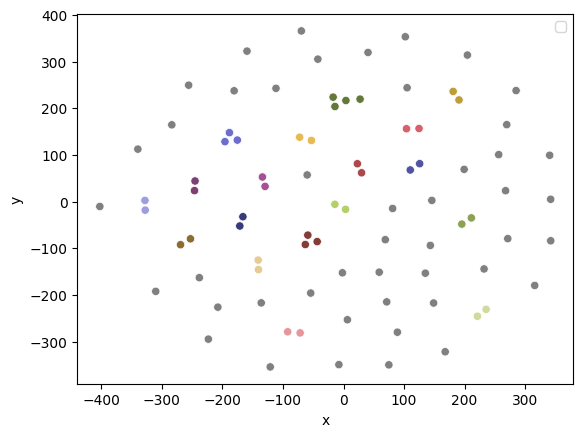

In [27]:
fig, ax = plt.subplots()
cd.plot_clonotype_clustering(color_by='cluster', ax=ax, plot_unclustered=True)
ax.legend([])

In [28]:
cd.pgens

,cdr3aa,pgen
0,CASSERSEQFF,5.804233e-08
1,CASSQDLNEQFF,9.684847e-08
2,CASSETSGRNEQFF,4.638189e-08
3,CASSEVGTQYF,1.983716e-08
4,CASSYGQPYNEQFF,9.591477e-09
...,...,...
81,CASSDLLAGTGELFF,1.000375e-08
82,CASSLSGRYYNEQFF,6.624837e-09
83,CASSLGDRVYGYTF,1.029361e-07
84,CASSLGQADTQYF,1.695689e-07


In [29]:
cd.clonotype_clustering

,cdr3aa,cluster
vertex ID,,
0,CASSERSEQFF,0
1,CASSESSEQFF,0
2,CASSQDLNEQFF,1
3,CASSETSGRNEQFF,2
4,CASSGTSGRNEQFF,2
...,...,...
81,CASSVGPGDTGELFF,59
82,CASSVDQGPYEQYF,60
83,CASSDLLAGTGELFF,61


In [30]:
indexes = [dataset.clonotype_usage_matrix.clonotype_to_matrix_index[x] for x in biomarkers]

In [31]:
df_for_clf = pd.DataFrame.sparse.from_spmatrix(
    dataset.clonotype_usage_matrix.clonotype_database_usage[:, indexes])

In [32]:
df_for_clf.columns = [x.cdr3aa for x in biomarkers]

In [33]:
df_for_clf = df_for_clf.astype(int)

In [34]:
df_for_clf['number_of_clones'] = [x.number_of_clones for x in dataset]
df_for_clf['covid'] = dataset.metadata.COVID_status
df_for_clf['folder'] = dataset.metadata.folder

In [35]:
df_for_clf

,CASSERSEQFF,CASSQDLNEQFF,CASSETSGRNEQFF,CASSEVGTQYF,CASSYGQPYNEQFF,CASSHPGLAGGPGQETQYF,CASSLVEGETQYF,CASSPGISTDTQYF,CASSPAVGYTF,CASSPQTGANTEAFF,...,CASSVDQGPYEQYF,CASSLPEGETQYF,CASSDLLAGTGELFF,CASSLSGRYYNEQFF,CASSLGDRVYGYTF,CASSLGQADTQYF,CASSALLAGGYNEQFF,number_of_clones,covid,folder
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,0,4067,COVID,2020/10_FMBA_NovaSeq5
1,0,0,1,1,1,0,1,2,0,0,...,0,1,0,0,1,0,0,16303,COVID,2020/10_FMBA_NovaSeq5
2,0,0,0,1,0,0,0,0,0,0,...,0,0,0,0,1,0,0,13754,healthy,2020/10_FMBA_NovaSeq5
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,5893,COVID,2020/10_FMBA_NovaSeq5
4,0,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,10114,healthy,2020/12_FMBA_Novaseq8_DNA
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
537,0,2,0,0,0,0,1,0,0,3,...,0,0,0,0,1,1,0,25554,COVID,2020/12_FMBA_Novaseq8_DNA
538,1,0,0,0,0,0,0,1,0,0,...,0,0,0,0,0,1,0,10576,COVID,2020/12_FMBA_Novaseq8_DNA
539,0,0,0,0,0,0,0,3,1,0,...,0,0,0,0,0,0,0,12081,COVID,2020/12_FMBA_Novaseq7_DNA
540,0,1,0,0,0,0,0,0,0,0,...,0,0,0,0,1,0,0,5969,COVID,2020/10_FMBA_NovaSeq6


---

# Classifier training and evaluation

The cells below correspond to the original `grid_search_clf.ipynb` notebook and perform grid search, model training, and evaluation using the biomarker-based feature matrix.

In [36]:
# import sys
# sys.path.append("../")
from mir.common.repertoire_dataset import RepertoireDataset
from mir.common.clonotype import ClonotypeAA
from mir.common.repertoire import Repertoire
from mir.biomarkers.fisher_biomarkers_detector import FisherBiomarkersDetector
from mir.ml.grid_search_classifier import GridSearchClassifier, CustomMLModel
from mir.common.clonotype_dataset import ClonotypeDataset
import pandas as pd

# grid search classifier usage example
## here we would predict donor COVID-19 status based on a set of TCR beta biomarkers

In [37]:
df = df_for_clf
df

,CASSERSEQFF,CASSQDLNEQFF,CASSETSGRNEQFF,CASSEVGTQYF,CASSYGQPYNEQFF,CASSHPGLAGGPGQETQYF,CASSLVEGETQYF,CASSPGISTDTQYF,CASSPAVGYTF,CASSPQTGANTEAFF,...,CASSVDQGPYEQYF,CASSLPEGETQYF,CASSDLLAGTGELFF,CASSLSGRYYNEQFF,CASSLGDRVYGYTF,CASSLGQADTQYF,CASSALLAGGYNEQFF,number_of_clones,covid,folder
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,0,4067,COVID,2020/10_FMBA_NovaSeq5
1,0,0,1,1,1,0,1,2,0,0,...,0,1,0,0,1,0,0,16303,COVID,2020/10_FMBA_NovaSeq5
2,0,0,0,1,0,0,0,0,0,0,...,0,0,0,0,1,0,0,13754,healthy,2020/10_FMBA_NovaSeq5
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,5893,COVID,2020/10_FMBA_NovaSeq5
4,0,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,10114,healthy,2020/12_FMBA_Novaseq8_DNA
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
537,0,2,0,0,0,0,1,0,0,3,...,0,0,0,0,1,1,0,25554,COVID,2020/12_FMBA_Novaseq8_DNA
538,1,0,0,0,0,0,0,1,0,0,...,0,0,0,0,0,1,0,10576,COVID,2020/12_FMBA_Novaseq8_DNA
539,0,0,0,0,0,0,0,3,1,0,...,0,0,0,0,0,0,0,12081,COVID,2020/12_FMBA_Novaseq7_DNA
540,0,1,0,0,0,0,0,0,0,0,...,0,0,0,0,1,0,0,5969,COVID,2020/10_FMBA_NovaSeq6


In [38]:
normalized_df = pd.concat([df.drop(columns=['covid', 'folder', 'number_of_clones']).div(df.number_of_clones, axis=0),
                          df[['covid', 'folder']]], axis=1)

In [39]:
normalized_df['label'] = normalized_df['covid'].apply(lambda x: 1 if x == 'COVID' else 0)

In [40]:
normalized_df

,CASSERSEQFF,CASSQDLNEQFF,CASSETSGRNEQFF,CASSEVGTQYF,CASSYGQPYNEQFF,CASSHPGLAGGPGQETQYF,CASSLVEGETQYF,CASSPGISTDTQYF,CASSPAVGYTF,CASSPQTGANTEAFF,...,CASSVDQGPYEQYF,CASSLPEGETQYF,CASSDLLAGTGELFF,CASSLSGRYYNEQFF,CASSLGDRVYGYTF,CASSLGQADTQYF,CASSALLAGGYNEQFF,covid,folder,label
0,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,...,0.0,0.000000,0.0,0.0,0.000000,0.000246,0.0,COVID,2020/10_FMBA_NovaSeq5,1
1,0.000000,0.000000,0.000061,0.000061,0.000061,0.0,0.000061,0.000123,0.000000,0.000000,...,0.0,0.000061,0.0,0.0,0.000061,0.000000,0.0,COVID,2020/10_FMBA_NovaSeq5,1
2,0.000000,0.000000,0.000000,0.000073,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,...,0.0,0.000000,0.0,0.0,0.000073,0.000000,0.0,healthy,2020/10_FMBA_NovaSeq5,0
3,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,...,0.0,0.000000,0.0,0.0,0.000000,0.000000,0.0,COVID,2020/10_FMBA_NovaSeq5,1
4,0.000000,0.000099,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,...,0.0,0.000000,0.0,0.0,0.000000,0.000000,0.0,healthy,2020/12_FMBA_Novaseq8_DNA,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
537,0.000000,0.000078,0.000000,0.000000,0.000000,0.0,0.000039,0.000000,0.000000,0.000117,...,0.0,0.000000,0.0,0.0,0.000039,0.000039,0.0,COVID,2020/12_FMBA_Novaseq8_DNA,1
538,0.000095,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000095,0.000000,0.000000,...,0.0,0.000000,0.0,0.0,0.000000,0.000095,0.0,COVID,2020/12_FMBA_Novaseq8_DNA,1
539,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000248,0.000083,0.000000,...,0.0,0.000000,0.0,0.0,0.000000,0.000000,0.0,COVID,2020/12_FMBA_Novaseq7_DNA,1
540,0.000000,0.000168,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,...,0.0,0.000000,0.0,0.0,0.000168,0.000000,0.0,COVID,2020/10_FMBA_NovaSeq6,1


In [41]:
from sklearn.linear_model import LogisticRegression

In [42]:
gsc = GridSearchClassifier(used_models=['svm', 'knn', 'rfc', 'xgboost'], 
                           custom_models=[CustomMLModel(model_name='lr',
                                                        model_object=LogisticRegression(),
                                                        model_hyperparams={
                                                            'penalty': ['l1', 'l2'],
                                                            'solver': ['liblinear', 'saga']
                                                        })])

# do the random split

In [43]:
normalized_df

,CASSERSEQFF,CASSQDLNEQFF,CASSETSGRNEQFF,CASSEVGTQYF,CASSYGQPYNEQFF,CASSHPGLAGGPGQETQYF,CASSLVEGETQYF,CASSPGISTDTQYF,CASSPAVGYTF,CASSPQTGANTEAFF,...,CASSVDQGPYEQYF,CASSLPEGETQYF,CASSDLLAGTGELFF,CASSLSGRYYNEQFF,CASSLGDRVYGYTF,CASSLGQADTQYF,CASSALLAGGYNEQFF,covid,folder,label
0,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,...,0.0,0.000000,0.0,0.0,0.000000,0.000246,0.0,COVID,2020/10_FMBA_NovaSeq5,1
1,0.000000,0.000000,0.000061,0.000061,0.000061,0.0,0.000061,0.000123,0.000000,0.000000,...,0.0,0.000061,0.0,0.0,0.000061,0.000000,0.0,COVID,2020/10_FMBA_NovaSeq5,1
2,0.000000,0.000000,0.000000,0.000073,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,...,0.0,0.000000,0.0,0.0,0.000073,0.000000,0.0,healthy,2020/10_FMBA_NovaSeq5,0
3,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,...,0.0,0.000000,0.0,0.0,0.000000,0.000000,0.0,COVID,2020/10_FMBA_NovaSeq5,1
4,0.000000,0.000099,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,...,0.0,0.000000,0.0,0.0,0.000000,0.000000,0.0,healthy,2020/12_FMBA_Novaseq8_DNA,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
537,0.000000,0.000078,0.000000,0.000000,0.000000,0.0,0.000039,0.000000,0.000000,0.000117,...,0.0,0.000000,0.0,0.0,0.000039,0.000039,0.0,COVID,2020/12_FMBA_Novaseq8_DNA,1
538,0.000095,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000095,0.000000,0.000000,...,0.0,0.000000,0.0,0.0,0.000000,0.000095,0.0,COVID,2020/12_FMBA_Novaseq8_DNA,1
539,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000248,0.000083,0.000000,...,0.0,0.000000,0.0,0.0,0.000000,0.000000,0.0,COVID,2020/12_FMBA_Novaseq7_DNA,1
540,0.000000,0.000168,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,...,0.0,0.000000,0.0,0.0,0.000168,0.000000,0.0,COVID,2020/10_FMBA_NovaSeq6,1


In [44]:
normalized_df.sum()[:-3].min()

0.0012063704576344859

In [45]:
gsc.specify_data_and_split(normalized_df, 
                           y='label', 
                           splitting_method=0.2, 
                           drop_columns=['covid', 'folder'])

In [46]:
LogisticRegression().get_params()

{'C': 1.0,
 'class_weight': None,
 'dual': False,
 'fit_intercept': True,
 'intercept_scaling': 1,
 'l1_ratio': None,
 'max_iter': 100,
 'multi_class': 'deprecated',
 'n_jobs': None,
 'penalty': 'l2',
 'random_state': None,
 'solver': 'lbfgs',
 'tol': 0.0001,
 'verbose': 0,
 'warm_start': False}

In [47]:
gsc.evaluate_models(debug=True)

Started evaluating svm
Best params for svm: {'C': 1, 'kernel': 'rbf', 'probability': True, 'random_state': 42}
Test f1-score for the best model 0.88

Started evaluating knn
Best params for knn: {'leaf_size': 1, 'n_neighbors': 3, 'weights': 'uniform'}
Test f1-score for the best model 0.50

Started evaluating rfc
Best params for rfc: {'max_depth': 3, 'min_samples_leaf': 8, 'n_estimators': 125, 'n_jobs': -1, 'oob_score': False, 'random_state': 42}
Test f1-score for the best model 0.78

Started evaluating xgboost


/home/evlasova/.conda/envs/bio2025/lib/python3.12/site-packages/numpy/ma/core.py:2820: RuntimeWarning: invalid value encountered in cast
  _data = np.array(data, dtype=dtype, copy=copy,


Best params for xgboost: {'n_estimators': 50, 'n_jobs': -1, 'random_state': 42, 'subsample': 1}
Test f1-score for the best model 0.80

Started evaluating lr
Best params for lr: {'penalty': 'l1', 'random_state': 42, 'solver': 'liblinear'}
Test f1-score for the best model 0.84

classifier       svm      knn      rfc  xgboost        lr
f1-score    0.884058  0.49505  0.77907      0.8  0.844444
Best model is svm with params: {'C': 1, 'kernel': 'rbf', 'probability': True, 'random_state': 42}


/home/evlasova/.conda/envs/bio2025/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:349: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/evlasova/.conda/envs/bio2025/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:349: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/evlasova/.conda/envs/bio2025/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:349: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/evlasova/.conda/envs/bio2025/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:349: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/evlasova/.conda/envs/bio2025/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:349: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home

({'svm': SVC(C=1, probability=True, random_state=42),
  'knn': KNeighborsClassifier(leaf_size=1, n_neighbors=3),
  'rfc': RandomForestClassifier(max_depth=3, min_samples_leaf=8, n_estimators=125,
                         n_jobs=-1, random_state=42),
  'xgboost': XGBClassifier(base_score=None, booster=None, callbacks=None,
                colsample_bylevel=None, colsample_bynode=None,
                colsample_bytree=None, device=None, early_stopping_rounds=None,
                enable_categorical=False, eval_metric=None, feature_types=None,
                gamma=None, grow_policy=None, importance_type=None,
                interaction_constraints=None, learning_rate=None, max_bin=None,
                max_cat_threshold=None, max_cat_to_onehot=None,
                max_delta_step=None, max_depth=None, max_leaves=None,
                min_child_weight=None, missing=nan, monotone_constraints=None,
                multi_strategy=None, n_estimators=50, n_jobs=-1,
                num_paralle

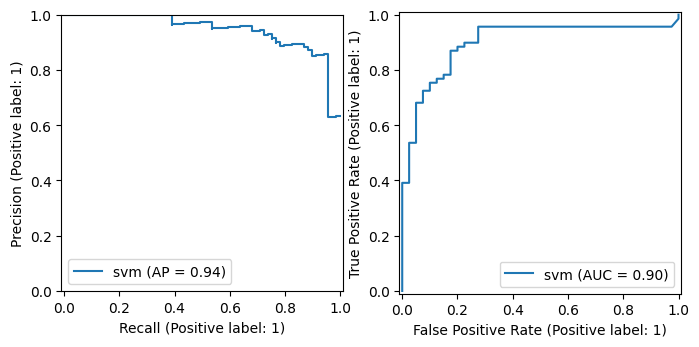

In [48]:
gsc.plot_curves_for_clf()

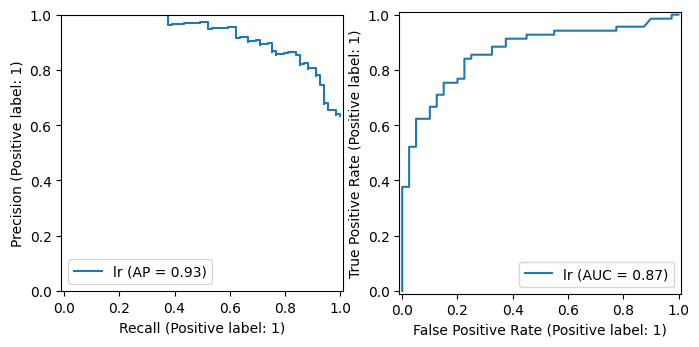

In [49]:
gsc.plot_curves_for_clf(name='lr')

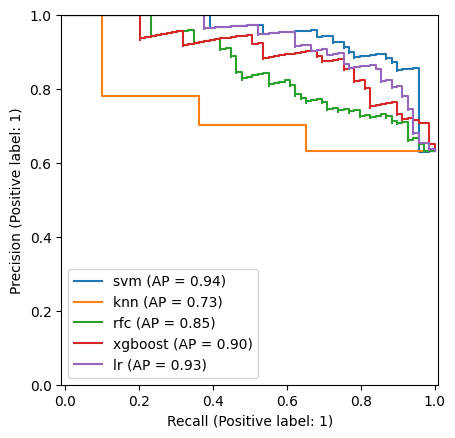

In [50]:
gsc.plot_curve_for_all_clfs()

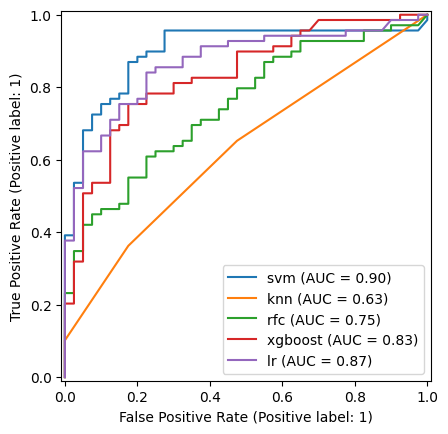

In [51]:
gsc.plot_curve_for_all_clfs(type='roc')

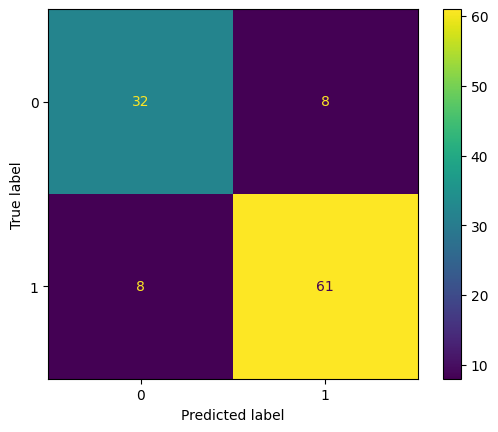

In [52]:
gsc.plot_confusion_matrix_for_clf(name='svm')

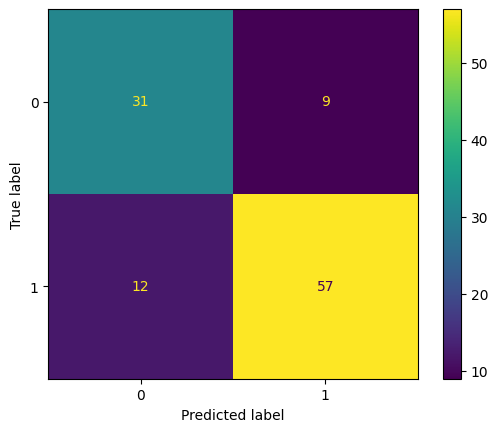

In [53]:
gsc.plot_confusion_matrix_for_clf(name='lr')

# split based on batch

In [60]:
gsc1 = GridSearchClassifier(used_models=['svm', 'rfc', 'xgboost'])

In [61]:
normalized_df.head()

,CASSERSEQFF,CASSQDLNEQFF,CASSETSGRNEQFF,CASSEVGTQYF,CASSYGQPYNEQFF,CASSHPGLAGGPGQETQYF,CASSLVEGETQYF,CASSPGISTDTQYF,CASSPAVGYTF,CASSPQTGANTEAFF,...,CASSVDQGPYEQYF,CASSLPEGETQYF,CASSDLLAGTGELFF,CASSLSGRYYNEQFF,CASSLGDRVYGYTF,CASSLGQADTQYF,CASSALLAGGYNEQFF,covid,folder,label
0,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.0,0.0,...,0.0,0.000000,0.0,0.0,0.000000,0.000246,0.0,COVID,2020/10_FMBA_NovaSeq5,1
1,0.0,0.000000,0.000061,0.000061,0.000061,0.0,0.000061,0.000123,0.0,0.0,...,0.0,0.000061,0.0,0.0,0.000061,0.000000,0.0,COVID,2020/10_FMBA_NovaSeq5,1
2,0.0,0.000000,0.000000,0.000073,0.000000,0.0,0.000000,0.000000,0.0,0.0,...,0.0,0.000000,0.0,0.0,0.000073,0.000000,0.0,healthy,2020/10_FMBA_NovaSeq5,0
3,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.0,0.0,...,0.0,0.000000,0.0,0.0,0.000000,0.000000,0.0,COVID,2020/10_FMBA_NovaSeq5,1
4,0.0,0.000099,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.0,0.0,...,0.0,0.000000,0.0,0.0,0.000000,0.000000,0.0,healthy,2020/12_FMBA_Novaseq8_DNA,0


In [62]:
# specifying the lambda function which would return True for train batch
gsc1.specify_data_and_split(normalized_df, 
                           y='label', 
                           splitting_method=lambda x: x.folder != '2020/10_FMBA_NovaSeq6', 
                           drop_columns=['covid', 'folder'])

In [63]:
gsc1.X_test

,CASSERSEQFF,CASSQDLNEQFF,CASSETSGRNEQFF,CASSEVGTQYF,CASSYGQPYNEQFF,CASSHPGLAGGPGQETQYF,CASSLVEGETQYF,CASSPGISTDTQYF,CASSPAVGYTF,CASSPQTGANTEAFF,...,CASSMGQPYNEQFF,CASSLPGTRTDTQYF,CASSVGPGDTGELFF,CASSVDQGPYEQYF,CASSLPEGETQYF,CASSDLLAGTGELFF,CASSLSGRYYNEQFF,CASSLGDRVYGYTF,CASSLGQADTQYF,CASSALLAGGYNEQFF
14,-0.34572,-0.442666,-0.327613,-0.466688,-0.284918,-0.177259,-0.648050,-0.730635,1.509102,1.040950,...,-0.251699,-0.315825,-0.244661,-0.304097,-0.401577,-0.170774,-0.336343,-0.514196,0.283423,-0.252881
94,-0.34572,-0.442666,3.010091,-0.466688,-0.284918,-0.177259,1.385142,-0.730635,-0.290594,2.440724,...,-0.251699,-0.315825,-0.244661,-0.304097,1.822454,7.150515,4.393872,-0.514196,1.264905,-0.252881
95,-0.34572,1.776756,-0.327613,0.819922,-0.284918,-0.177259,1.016382,-0.730635,-0.290594,1.925722,...,-0.251699,-0.315825,-0.244661,-0.304097,-0.401577,-0.170774,-0.336343,0.481861,0.903800,-0.252881
96,-0.34572,-0.442666,-0.327613,1.174929,-0.284918,-0.177259,0.413794,-0.730635,-0.290594,-0.398789,...,-0.251699,-0.315825,-0.244661,-0.304097,0.759934,-0.170774,-0.336343,0.756697,0.313721,-0.252881
97,-0.34572,1.236486,-0.327613,-0.466688,-0.284918,-0.177259,0.611212,-0.730635,-0.290594,-0.398789,...,-0.251699,-0.315825,-0.244661,-0.304097,0.975881,-0.170774,-0.336343,-0.514196,-0.726082,-0.252881
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
511,-0.34572,-0.442666,-0.327613,-0.466688,-0.284918,-0.177259,-0.648050,2.933202,-0.290594,-0.398789,...,-0.251699,-0.315825,-0.244661,-0.304097,-0.401577,-0.170774,-0.336343,1.305429,0.762676,-0.252881
516,-0.34572,-0.442666,-0.327613,-0.466688,-0.284918,-0.177259,-0.648050,-0.730635,-0.290594,-0.398789,...,-0.251699,-0.315825,-0.244661,-0.304097,-0.401577,-0.170774,-0.336343,-0.514196,-0.726082,-0.252881
517,-0.34572,-0.442666,-0.327613,-0.466688,-0.284918,-0.177259,0.466963,-0.730635,-0.290594,-0.398789,...,-0.251699,-0.315825,-0.244661,-0.304097,-0.401577,-0.170774,-0.336343,0.820333,0.365786,-0.252881
518,-0.34572,-0.442666,-0.327613,-0.466688,-0.284918,-0.177259,-0.648050,-0.730635,-0.290594,-0.398789,...,-0.251699,-0.315825,-0.244661,-0.304097,-0.401577,-0.170774,-0.336343,-0.514196,0.902805,-0.252881


In [64]:
gsc1.X_train

,CASSERSEQFF,CASSQDLNEQFF,CASSETSGRNEQFF,CASSEVGTQYF,CASSYGQPYNEQFF,CASSHPGLAGGPGQETQYF,CASSLVEGETQYF,CASSPGISTDTQYF,CASSPAVGYTF,CASSPQTGANTEAFF,...,CASSMGQPYNEQFF,CASSLPGTRTDTQYF,CASSVGPGDTGELFF,CASSVDQGPYEQYF,CASSLPEGETQYF,CASSDLLAGTGELFF,CASSLSGRYYNEQFF,CASSLGDRVYGYTF,CASSLGQADTQYF,CASSALLAGGYNEQFF
0,-0.345720,-0.442666,-0.327613,-0.466688,-0.284918,-0.177259,-0.648050,-0.730635,-0.290594,-0.398789,...,-0.251699,-0.315825,-0.244661,-0.304097,-0.401577,-0.170774,-0.336343,-0.514196,3.541787,-0.252881
1,-0.345720,-0.442666,1.457218,1.214200,2.126918,-0.177259,0.439196,1.016147,-0.290594,-0.398789,...,-0.251699,-0.315825,-0.244661,-0.304097,0.787720,-0.170774,-0.336343,0.787099,-0.726082,-0.252881
2,-0.345720,-0.442666,-0.327613,1.525715,-0.284918,-0.177259,-0.648050,-0.730635,-0.290594,-0.398789,...,-0.251699,-0.315825,-0.244661,-0.304097,-0.401577,-0.170774,-0.336343,1.028265,-0.726082,-0.252881
3,-0.345720,-0.442666,-0.327613,-0.466688,-0.284918,-0.177259,-0.648050,-0.730635,-0.290594,-0.398789,...,-0.251699,-0.315825,-0.244661,-0.304097,-0.401577,-0.170774,-0.336343,-0.514196,-0.726082,-0.252881
4,-0.345720,1.894267,-0.327613,-0.466688,-0.284918,-0.177259,-0.648050,-0.730635,-0.290594,-0.398789,...,-0.251699,-0.315825,-0.244661,-0.304097,-0.401577,-0.170774,-0.336343,-0.514196,-0.726082,-0.252881
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
536,-0.345720,-0.442666,-0.327613,-0.466688,-0.284918,-0.177259,-0.648050,-0.730635,-0.290594,-0.398789,...,-0.251699,-0.315825,-0.244661,-0.304097,-0.401577,-0.170774,-0.336343,-0.514196,-0.726082,-0.252881
537,-0.345720,1.407200,-0.327613,-0.466688,-0.284918,-0.177259,0.045594,-0.730635,-0.290594,2.507395,...,-0.251699,1.021211,-0.244661,-0.304097,-0.401577,-0.170774,-0.336343,0.316007,-0.046837,-0.252881
538,2.525711,-0.442666,-0.327613,-0.466688,-0.284918,-0.177259,-0.648050,0.615705,-0.290594,-0.398789,...,-0.251699,-0.315825,-0.244661,-0.304097,-0.401577,-0.170774,-0.336343,-0.514196,0.915127,-0.252881
539,-0.345720,-0.442666,-0.327613,-0.466688,-0.284918,-0.177259,-0.648050,2.805221,2.270781,-0.398789,...,-0.251699,-0.315825,3.432186,-0.304097,-0.401577,-0.170774,-0.336343,-0.514196,-0.726082,-0.252881


In [65]:
gsc1.evaluate_models(debug=True)

Started evaluating svm
Best params for svm: {'C': 1, 'kernel': 'sigmoid', 'probability': True, 'random_state': 42}
Test f1-score for the best model 0.73

Started evaluating rfc
Best params for rfc: {'max_depth': 3, 'min_samples_leaf': 8, 'n_estimators': 125, 'n_jobs': -1, 'oob_score': False, 'random_state': 42}
Test f1-score for the best model 0.63

Started evaluating xgboost
Best params for xgboost: {'n_estimators': 25, 'n_jobs': -1, 'random_state': 42, 'subsample': 0.5}
Test f1-score for the best model 0.60

classifier       svm       rfc   xgboost
f1-score    0.728972  0.627219  0.604651
Best model is svm with params: {'C': 1, 'kernel': 'sigmoid', 'probability': True, 'random_state': 42}


/home/evlasova/.conda/envs/bio2025/lib/python3.12/site-packages/numpy/ma/core.py:2820: RuntimeWarning: invalid value encountered in cast
  _data = np.array(data, dtype=dtype, copy=copy,


({'svm': SVC(C=1, kernel='sigmoid', probability=True, random_state=42),
  'rfc': RandomForestClassifier(max_depth=3, min_samples_leaf=8, n_estimators=125,
                         n_jobs=-1, random_state=42),
  'xgboost': XGBClassifier(base_score=None, booster=None, callbacks=None,
                colsample_bylevel=None, colsample_bynode=None,
                colsample_bytree=None, device=None, early_stopping_rounds=None,
                enable_categorical=False, eval_metric=None, feature_types=None,
                gamma=None, grow_policy=None, importance_type=None,
                interaction_constraints=None, learning_rate=None, max_bin=None,
                max_cat_threshold=None, max_cat_to_onehot=None,
                max_delta_step=None, max_depth=None, max_leaves=None,
                min_child_weight=None, missing=nan, monotone_constraints=None,
                multi_strategy=None, n_estimators=25, n_jobs=-1,
                num_parallel_tree=None, random_state=42, ...)},
 'sv

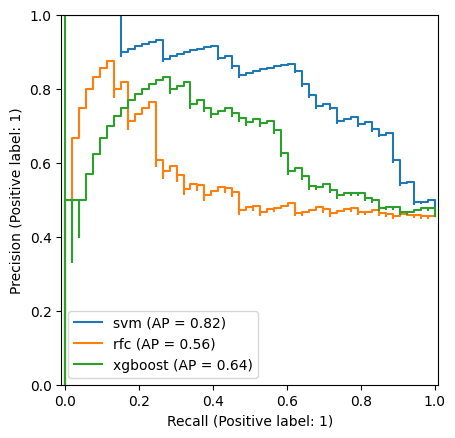

In [66]:
gsc1.plot_curve_for_all_clfs()

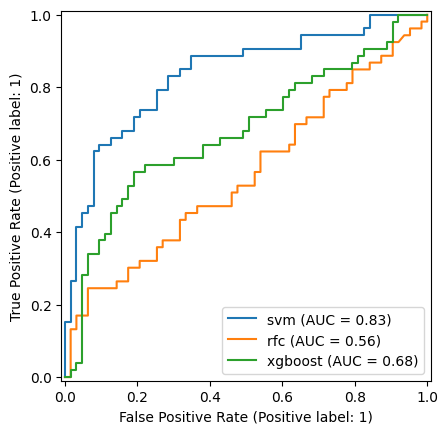

In [68]:
gsc1.plot_curve_for_all_clfs(type='roc')

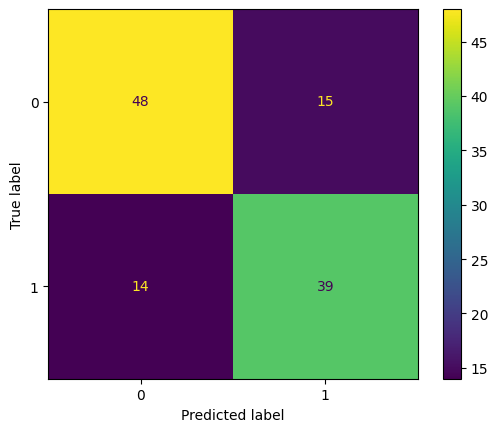

In [69]:
gsc1.plot_confusion_matrix_for_clf(name='svm')